# ML2. Обучение с учителем — линейная регрессия

## **Задание 1. Ответы на вопросы (теория)**

### ⬇️ Задание 1.1. *Выведите аналитическое решение задачи регрессии. Используйте векторную форму уравнения.*  

Умножение матрицы X на вектор весов w сразу = вектор всех предсказаний (по одному на каждый объект):

$$
\hat{\mathbf{y}} = X\mathbf{w}
$$

Размерности: X имеет размер **N × (d+1),** а  w **(d+1) × 1**, значит результат - **N×1**, то есть как раз столбик из N предсказаний.  
Сумма квадратов в векторной форме - это квадрат длины вектора ошибок **e = y − Xw:**

$$
\mathrm{RSS}(\mathbf{w}) = \lVert \mathbf{y} - X\mathbf{w} \rVert^2
$$

то есть:

$$
\mathrm{RSS}(\mathbf{w}) = (\mathbf{y} - X\mathbf{w})^T (\mathbf{y} - X\mathbf{w})
$$

В README записана **MSE = (1/N) · RSS**. Множитель 1/N — положительная константа; он не сдвигает точку минимума, поэтому минимизация MSE и RSS даёт одни и те же веса. Для удобства выводим через RSS.  

Поскольку переменных много (целый вектор w), вместо одной производной берём градиент — вектор из производных по каждому весу — и приравниваем к нулю:

$$
\nabla_{\mathbf{w}}\,\mathrm{RSS}(\mathbf{w}) = \mathbf{0}
$$

Раскроем произведение (y − Xw)^T (y − Xw) как обычный квадрат разности:

$$
\mathrm{RSS}(\mathbf{w}) =
\mathbf{y}^T\mathbf{y}
- \mathbf{y}^T X\mathbf{w}
- \mathbf{w}^T X^T \mathbf{y}
+ \mathbf{w}^T X^T X \mathbf{w}
$$

Два средних слагаемых — это одно и то же число, записанное двумя способами:

$$
-\mathbf{y}^T\, X\mathbf{w}\,-\mathbf{w}^T X^T \mathbf{y} = -2 \mathbf{w}^T X^T \mathbf{y}
$$

Сокращаем и объединяем их:

$$
\mathrm{RSS}(\mathbf{w}) = \mathbf{y}^T\mathbf{y} - 2\,\mathbf{w}^T X^T \mathbf{y} + \mathbf{w}^T X^T X \mathbf{w}
$$

Структура как с обычным школьным квадратом. Дифференцируем RSS(w) по w, разбирая каждое слагаемое:

- y^T y          — не содержит w  →  градиент 0;
- −2 w^T X^T y    — линейно по w   →  градиент −2 X^T y;
- w^T (X^T X) w   — квадратично    →  градиент 2 (X^T X) w.

Складываем:

$$
\nabla_{\mathbf{w}}\,\mathrm{RSS}(\mathbf{w})
= -2\,X^T \mathbf{y} + 2\,X^T X \mathbf{w}
$$

Приравниваем градиент к нулевому вектору (условие дна чаши):

$$
-2\,X^T \mathbf{y} + 2\,X^T X \mathbf{w} = \mathbf{0}
$$

Делим обе части на 2 и переносим:

$$
X^T X\,\mathbf{w} = X^T \mathbf{y}
$$

Получаем нормальное уравнение.

«Поделить» на матрицу X^T X — значит умножить слева на обратную к ней матрицу (X^T X)^{-1}.  
Получаем итоговое аналитическое решение:

$$
\boxed{\;\mathbf{w} = \left(X^T X\right)^{-1} X^T \mathbf{y}\;}
$$

### ⬇️ Задание 1.2. *Что меняется в решении, когда в функцию потерь добавляются L1- и L2-регуляризации.*

К функции потерь мы добавляем штрафное слагаемое, которое растёт, когда веса становятся большими.  

$$
RSS(w) + \lambda * R(w)
$$

RSS(w) - ошибка,  
R(w) - функция штрафа (выбираем L1 или L2),  
λ - сила штрафа.

Функция потерь выглядит так:
$$
Loss(\mathbf{w}) = \underbrace{\sum_{i=1}^{N}\bigl(y_i - \mathbf{w}^T x_i\bigr)^2}_{\mathrm{RSS}(\mathbf{w})} + \lambda\, R(\mathbf{w})
$$

Минимизация w (общая формула):

$$
\min_{\mathbf{w}}\ \sum_{i=1}^{N} L\bigl(f(x_i, \mathbf{w}),\, y_i\bigr) + \lambda\, R(\mathbf{w})
$$

*L* - какая-либо функция потерь,  
*f* - какая-либо модель

Два варианта штрафа R(w) — L1 и L2:
$$
R_{L1}(\mathbf{w}) = \lVert \mathbf{w} \rVert_1 = \sum_{i=1}^{d} |w_i|
\qquad
R_{L2}(\mathbf{w}) = \lVert \mathbf{w} \rVert_2^2 = \sum_{i=1}^{d} w_i^2
$$


### ⬇️ Задание 1.3. *Объясните, почему L1-регуляризацию часто используют для отбора признаков. Почему после подгонки модели многие веса равны 0?*

Каждый ненулевой коэффициент добавляет штраф, поэтому слабым (бесполезным) признакам выгодно иметь вес ровно 0.  

$$
R(w) = \underbrace{\lVert w \rVert_1}_{\text{L1-норма}} = \sum_{i=1}^{d} |w_i|
$$

### ⬇️ Задание 1.4. *Объясните, как можно использовать те же модели (Линейная регрессия, Ridge и т. д.), но сделать возможным подгонку нелинейных зависимостей.*

Модель линейна **по весам**, но не обязана быть линейной по исходным признакам. По прошлому заданию ML1_Introduction можно использовать полиноминальные признаки или применять логарифмы, экспоненты и т.п.  
Линейная регрессия остаётся линейной, но с помощтю полиноминальных признаков теперь ещё может изгибаться как парабола


## **Задание 2. Введение — выполните всю предобработку из предыдущего занятия**

### ⬇️ Задание 2.1. Импорт библиотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import MinMaxScaler, StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# воспроизводимость и аккуратный вывод
RANDOM_STATE = 21
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda v: f'{v:.6f}')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
np.random.seed(RANDOM_STATE)

### ⬇️ Задание 2.2. Прочитайте обучающую и тестовую части.  

In [2]:
df = pd.read_json('../datasets/train.json')
print(f'Размер исходного датасета: {df.shape}')
df.head(3)

Размер исходного датасета: (49352, 15)


,bathrooms,bedrooms,building_id,created,description,display_address,features,latitude,listing_id,longitude,manager_id,photos,price,street_address,interest_level
4,1.000000,1,8579a0b0d54db803821a35a4a615e97a,2016-06-16 05:55:27,Spacious 1 Bedroom 1 Bathroom in Williamsburg!...,145 Borinquen Place,"[Dining Room, Pre-War, Laundry in Building, Di...",40.710800,7170325,-73.953900,a10db4590843d78c784171a107bdacb4,[https://photos.renthop.com/2/7170325_3bb5ac84...,2400,145 Borinquen Place,medium
6,1.000000,2,b8e75fc949a6cd8225b455648a951712,2016-06-01 05:44:33,BRAND NEW GUT RENOVATED TRUE 2 BEDROOMFind you...,East 44th,"[Doorman, Elevator, Laundry in Building, Dishw...",40.751300,7092344,-73.972200,955db33477af4f40004820b4aed804a0,[https://photos.renthop.com/2/7092344_7663c19a...,3800,230 East 44th,low
9,1.000000,2,cd759a988b8f23924b5a2058d5ab2b49,2016-06-14 15:19:59,**FLEX 2 BEDROOM WITH FULL PRESSURIZED WALL**L...,East 56th Street,"[Doorman, Elevator, Laundry in Building, Laund...",40.757500,7158677,-73.962500,c8b10a317b766204f08e613cef4ce7a0,[https://photos.renthop.com/2/7158677_c897a134...,3495,405 East 56th Street,medium


In [3]:
df.info()

<class 'pandas.DataFrame'>
Index: 49352 entries, 4 to 124009
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   bathrooms        49352 non-null  float64
 1   bedrooms         49352 non-null  int64  
 2   building_id      49352 non-null  str    
 3   created          49352 non-null  str    
 4   description      49352 non-null  str    
 5   display_address  49352 non-null  str    
 6   features         49352 non-null  object 
 7   latitude         49352 non-null  float64
 8   listing_id       49352 non-null  int64  
 9   longitude        49352 non-null  float64
 10  manager_id       49352 non-null  str    
 11  photos           49352 non-null  object 
 12  price            49352 non-null  int64  
 13  street_address   49352 non-null  str    
 14  interest_level   49352 non-null  str    
dtypes: float64(3), int64(3), object(2), str(7)
memory usage: 6.0+ MB


Как в ML1 отрезаем хвосты по 1-му и 99-му перцентилю.

In [4]:
# Вычисляем границы по 1 и 99 процентилям
q_low, q_high = df['price'].quantile([0.01, 0.99])
print(f'\n1%-процентиль = {q_low:.0f}, 99%-процентиль = {q_high:.0f}')

df = df[(df['price'] >= q_low) & (df['price'] <= q_high)].copy()
print(f'Размер датасета после удаления выбросов: {df.shape}')


1%-процентиль = 1475, 99%-процентиль = 13000
Размер датасета после удаления выбросов: (48379, 15)


## **Задание 3. Первичный анализ данных, часть 2**

### ⬇️ Задание 3.1. Сгенерируем дополнительные признаки для повышения качества модели. Рассмотрите столбец `Features`. Он состоит из списка особенностей текущей квартиры.

In [5]:
df['features'].explode().str.strip().value_counts()

features
Elevator                                                                                                              25398
Hardwood Floors                                                                                                       23159
Cats Allowed                                                                                                          23148
Dogs Allowed                                                                                                          21662
Doorman                                                                                                               20497
                                                                                                                      ...  
Private Balcony                                                                                                           1
1.5 Marble Baths                                                                                                          1

### ⬇️ Задание 3.2. Удалите ненужные символы ([,], ', " и пробел) из столбца.

In [6]:
def clean_features(feature_list):
    text = str(feature_list)
    for ch in ['[',']', "'", '"', ' ']:
        text = text.replace(ch, '')
    return text.split(',')

print('Было: ', df['features'].iloc[0])
print('Стало:', clean_features(df['features'].iloc[0]))

Было:  ['Dining Room', 'Pre-War', 'Laundry in Building', 'Dishwasher', 'Hardwood Floors', 'Dogs Allowed', 'Cats Allowed']
Стало: ['DiningRoom', 'Pre-War', 'LaundryinBuilding', 'Dishwasher', 'HardwoodFloors', 'DogsAllowed', 'CatsAllowed']


In [7]:
for item in clean_features(df['features'].iloc[0]):
    print(item)

DiningRoom
Pre-War
LaundryinBuilding
Dishwasher
HardwoodFloors
DogsAllowed
CatsAllowed


### ⬇️ Задание 3.3. Получите все значения в каждом списке и соберите результат в один большой список по всему датасету. Можно использовать `DataFrame.iterrows()`.

### ⬇️ Задание 3.4. Сколько уникальных значений содержит итоговый список?

In [8]:
df_train, df_test = train_test_split(df, test_size=0.25, random_state=RANDOM_STATE)
df_train = df_train.copy()
df_test = df_test.copy()
print(f'df_train: {df_train.shape}, df_test: {df_test.shape}')

# собираем все значения в один большой список по train выборке
all_features = []
for _, row in df_train.iterrows():
    all_features.extend(clean_features(row['features']))

print(f'Всего значений в большом списке: {len(all_features)}')
print(f'Уникальных значений: {len(set(all_features))}')

df_train: (36284, 15), df_test: (12095, 15)
Всего значений в большом списке: 198899
Уникальных значений: 1278


### ⬇️ Задание 3.5. Познакомимся с новой библиотекой — Collections. С её помощью можно эффективно получить количественную статистику по данным.

`collections.Counter` за один проход считает, сколько раз встретилось каждое удобство.

### ⬇️ Задание 3.6. Подсчитайте самые популярные функции из нашего большого списка и возьмите топ-20 на данный момент.

Метод `.most_common(21)` берём с запасом (21), потому что среди частых значений есть пустая строка `''` - её отбрасываем и оставляем 20 удобств.

### ⬇️ Задание 3.7. Если всё сделано правильно, вы должны получить такие значения:  
'Elevator', 'CatsAllowed', 'HardwoodFloors', 'DogsAllowed', 'Doorman', 'Dishwasher', 'NoFee', 'LaundryinBuilding', 'FitnessCenter', 'Pre-War', 'LaundryinUnit', 'RoofDeck', 'OutdoorSpace', 'DiningRoom', 'HighSpeedInternet', 'Balcony', 'SwimmingPool', 'LaundryInBuilding', 'NewConstruction', 'Terrace'.

In [9]:
cnt = Counter(all_features)
display(cnt.most_common(21))

top_features = [name for name, _ in cnt.most_common(21) if name != ''][:20]
print(f'Топ-20 удобств ({len(top_features)}):')
# print(top_features)

[('Elevator', 18977),
 ('HardwoodFloors', 17319),
 ('CatsAllowed', 17308),
 ('DogsAllowed', 16197),
 ('Doorman', 15342),
 ('Dishwasher', 15004),
 ('NoFee', 13419),
 ('LaundryinBuilding', 11996),
 ('FitnessCenter', 9715),
 ('Pre-War', 6748),
 ('LaundryinUnit', 6295),
 ('RoofDeck', 4797),
 ('OutdoorSpace', 3871),
 ('DiningRoom', 3682),
 ('HighSpeedInternet', 3141),
 ('', 2380),
 ('Balcony', 2196),
 ('SwimmingPool', 1979),
 ('LaundryInBuilding', 1923),
 ('NewConstruction', 1854),
 ('Terrace', 1651)]

Топ-20 удобств (20):


### ⬇️ Задание 3.8. Теперь создайте 20 новых признаков на основе топ-20 значений: 1, если значение есть в столбце `Features`, иначе 0.

In [10]:
for feature_name in top_features:
    df_train[feature_name] = df_train['features'].apply(
        lambda lst: 1 if feature_name in clean_features(lst) else 0
    )
    df_test[feature_name] = df_test['features'].apply(
        lambda lst: 1 if feature_name in clean_features(lst) else 0
    )
df_train[top_features].head(3)

,Elevator,HardwoodFloors,CatsAllowed,DogsAllowed,Doorman,Dishwasher,NoFee,LaundryinBuilding,FitnessCenter,Pre-War,LaundryinUnit,RoofDeck,OutdoorSpace,DiningRoom,HighSpeedInternet,Balcony,SwimmingPool,LaundryInBuilding,NewConstruction,Terrace
7640,1,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0
77726,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
31844,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0


### ⬇️ Задание 3.9. Расширьте наш набор признаков значениями `'bathrooms'`, `'bedrooms'` и создайте специальную переменную `feature_list` со всеми именами признаков. Теперь у нас 22 значения. Все модели должны обучаться на этих 22 признаках. 

In [11]:
feature_list = top_features + ['bathrooms', 'bedrooms']
print(f'Количество признаков: {len(feature_list)}')

X_train = df_train[feature_list].copy()
y_train = df_train['price'].copy()
X_test = df_test[feature_list].copy()
y_test = df_test['price'].copy()
print(f'X_train: {X_train.shape}, X_test: {X_test.shape}')

Количество признаков: 22
X_train: (36284, 22), X_test: (12095, 22)


Заведём три итоговые таблицы метрик (как в ML1): по MAE, RMSE и R². Будем дополнять их по ходу работы.
Также сделаем удобную функцию, считающую все три метрики сразу.

In [12]:
result_MAE = pd.DataFrame(columns=['model', 'train', 'test'])
result_RMSE = pd.DataFrame(columns=['model', 'train', 'test'])
result_R2 = pd.DataFrame(columns=['model', 'train', 'test'])

def add_result(name, y_tr, p_tr, y_te, p_te):
    '''Считает MAE/RMSE/R2 на train и test и дописывает строку во все три таблицы.'''
    result_MAE.loc[len(result_MAE)] = [name,
                                        mean_absolute_error(y_tr, p_tr),
                                        mean_absolute_error(y_te, p_te)]
    result_RMSE.loc[len(result_RMSE)] = [name,
                                         mean_squared_error(y_tr, p_tr) ** 0.5,
                                         mean_squared_error(y_te, p_te) ** 0.5]
    result_R2.loc[len(result_R2)] = [name,
                                     r2_score(y_tr, p_tr),
                                     r2_score(y_te, p_te)]

## **Задание 4. Реализация моделей — линейная регрессия**

### ⬇️ Задание 4.1. Реализуйте Python-класс для алгоритма линейной регрессии с двумя базовыми методами — fit и predict. Используйте стохастический градиентный спуск (SGD) для поиска оптимальных весов модели. Для лучшего понимания рекомендуем реализовать отдельные версии алгоритма с аналитическим решением и нестохастическим градиентным спуском под капотом.

Идея SGD: вместо того чтобы считать градиент по всей выборке, берём небольшую случайную порцию объектов
(`batch_size`) и делаем по ней шаг. Это быстро и хорошо масштабируется.

У нас есть признаки супер разного масштаба - флаги 0/1 и `bathrooms` 1-10, а таргет - тысячи долларов.
Чтобы SGD сходился устойчиво, внутри класса *стандартизируем признаки* - запоминаем среднее и std на train.

В этот же класс сразу заложим регуляризацию (`reg = None / 'l2' / 'l1' / 'elastic'`), а также аналитическое решение (`fit_analytic`).

In [13]:
class MyLinearRegression:
    '''Линейная регрессия с обучением через SGD (mini-batch).
    reg: None | 'l2' (Ridge) | 'l1' (Lasso) | 'elastic' (ElasticNet).
    Признаки стандартизуются внутри для устойчивой сходимости.'''

    def __init__(self, learning_rate=0.05, n_epochs=30, batch_size=32,
                 reg=None, alpha=0.0, l1_ratio=0.5, random_state=21):
        self.learning_rate = learning_rate
        self.n_epochs = n_epochs
        self.batch_size = batch_size
        self.reg = reg
        self.alpha = alpha
        self.l1_ratio = l1_ratio
        self.random_state = random_state

    def _scale_fit(self, X):
        # запоминаем статистику train для стандартизации
        self._mu = X.mean(axis=0)
        self._sigma = X.std(axis=0)
        self._sigma[self._sigma == 0] = 1.0  # защита от деления на ноль

    def _scale(self, X):
        return (X - self._mu) / self._sigma

    def _reg_grad(self):
        # добавка к градиенту весов от регуляризации
        if self.reg == 'l2':
            return self.alpha * self.w
        if self.reg == 'l1':
            return self.alpha * np.sign(self.w)
        if self.reg == 'elastic':
            return self.alpha * (self.l1_ratio * np.sign(self.w)
                                 + (1 - self.l1_ratio) * self.w)
        return 0.0

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self._scale_fit(X)
        Xs = self._scale(X)
        n, d = Xs.shape
        rng = np.random.RandomState(self.random_state)  # делает SGD детерминированным
        self.w = np.zeros(d)
        self.b = 0.0
        for _ in range(self.n_epochs):
            order = rng.permutation(n)  # перемешиваем объекты
            for start in range(0, n, self.batch_size):
                idx = order[start:start + self.batch_size]
                xb, yb = Xs[idx], y[idx]
                error = (xb @ self.w + self.b) - yb
                grad_w = (xb.T @ error) / len(idx) + self._reg_grad()
                grad_b = error.mean()
                self.w -= self.learning_rate * grad_w
                self.b -= self.learning_rate * grad_b
        return self

    def fit_analytic(self, X, y):
        '''Точное решение по нормальному уравнению theta = (XtX)^-1 Xt y (для L2 - с alpha*I).'''
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self._scale_fit(X)
        Xs = self._scale(X)
        Xb = np.hstack([np.ones((Xs.shape[0], 1)), Xs])  # столбец единиц под bias
        reg_matrix = np.zeros((Xb.shape[1], Xb.shape[1]))
        if self.reg == 'l2':
            reg_matrix = self.alpha * np.eye(Xb.shape[1])
            reg_matrix[0, 0] = 0.0  # bias не штрафуем
        theta = np.linalg.inv(Xb.T @ Xb + reg_matrix) @ Xb.T @ y
        self.b = theta[0]
        self.w = theta[1:]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self._scale(X) @ self.w + self.b

### ⬇️ Задание 4.2. Что такое детерминированная модель? Сделайте SGD детерминированным 

**Детерминированная** модель при одних и тех же входных данных и параметрах всегда даёт **один и тот же** результат.
SGD сам по себе случаен (перемешивает объекты), поэтому мы фиксируем генератор случайных чисел через
`np.random.RandomState(random_state)`.  
Проверим: два обучения с одним `random_state` дают идентичные веса.

In [14]:
m1 = MyLinearRegression(random_state=21).fit(X_train.values, y_train.values)
m2 = MyLinearRegression(random_state=21).fit(X_train.values, y_train.values)
print(f'Веса полностью совпадают: {np.allclose(m1.w, m2.w)}')
print(f'bias1 = {m1.b:.6f}, bias2 = {m2.b:.6f}')

Веса полностью совпадают: True
bias1 = 3517.257552, bias2 = 3517.257552


### ⬇️ Задание 4.3. Определите коэффициент детерминации (R²) и реализуйте функцию для его расчёта. 

$$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$
Сравнивает ошибку модели с ошибкой «наивного» предсказания средним. $R^2=1$ — идеал, $R^2=0$ — как среднее,
$R^2<0$ — хуже среднего. Реализуем сами и сверим со `sklearn`.

In [15]:
def my_r2_score(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    ss_res = ((y_true - y_pred) ** 2).sum()      # ошибка модели
    ss_tot = ((y_true - y_true.mean()) ** 2).sum()  # ошибка среднего
    return 1 - ss_res / ss_tot

# проверка: наш R2 == sklearn R2
check_pred = m1.predict(X_test.values)
print(f'my_r2     = {my_r2_score(y_test, check_pred):.6f}')
print(f'sklearn r2= {r2_score(y_test, check_pred):.6f}')

my_r2     = 0.570160
sklearn r2= 0.570160


### ⬇️ Задание 4.4. Сделайте предсказания вашим алгоритмом и оцените модель метриками MAE, RMSE и R²

In [16]:
my_lr = MyLinearRegression(random_state=RANDOM_STATE).fit(X_train.values, y_train.values)
pred_tr = my_lr.predict(X_train.values)
pred_te = my_lr.predict(X_test.values)

print('Своя линейная регрессия (SGD):')
print(f'  MAE  train={mean_absolute_error(y_train, pred_tr):.2f}  test={mean_absolute_error(y_test, pred_te):.2f}')
print(f'  RMSE train={mean_squared_error(y_train, pred_tr) ** 0.5:.2f}  test={mean_squared_error(y_test, pred_te) ** 0.5:.2f}')
print(f'  R2   train={my_r2_score(y_train, pred_tr):.4f}  test={my_r2_score(y_test, pred_te):.4f}')

Своя линейная регрессия (SGD):
  MAE  train=717.90  test=721.67
  RMSE train=1043.51  test=1048.31
  R2   train=0.5732  test=0.5702


### ⬇️ Задание 4.5 Инициализируйте `LinearRegression()` из `sklearn.linear_model`, обучите модель и сделайте предсказания на обучающей и тестовой частях, как в прошлом уроке.

### ⬇️ Задание 4.6. Сравните метрики качества и убедитесь, что разница небольшая (между вашими реализациями и sklearn).

In [17]:
sk_lr = LinearRegression().fit(X_train, y_train)
sk_pred_tr = sk_lr.predict(X_train)
sk_pred_te = sk_lr.predict(X_test)

print('sklearn LinearRegression:')
print(f'  RMSE train={mean_squared_error(y_train, sk_pred_tr) ** 0.5:.2f}  test={mean_squared_error(y_test, sk_pred_te) ** 0.5:.2f}')
print(f'  R2   test={r2_score(y_test, sk_pred_te):.4f}')

diff = abs(mean_squared_error(y_test, pred_te) ** 0.5 - mean_squared_error(y_test, sk_pred_te) ** 0.5)
rel = diff / (mean_squared_error(y_test, sk_pred_te) ** 0.5) * 100
print(f'\nОтставание своей модели по RMSE(test): {rel:.2f}% ')
print(f'R2 своей модели на test: {my_r2_score(y_test, pred_te):.4f}')

sklearn LinearRegression:
  RMSE train=1033.95  test=1039.85
  R2   test=0.5771

Отставание своей модели по RMSE(test): 0.81% 
R2 своей модели на test: 0.5702


### ⬇️ Задание 4.7. Сохраните метрики, как в прошлом уроке, в таблицу со столбцами model, train, test для таблиц MAE, RMSE и коэффициента R²

В сводные таблицы кладём метрики `sklearn`-моделей.  
Свои реализации мы уже проверили выше — они близки к `sklearn`.

In [18]:
add_result('Linreg default', y_train, sk_pred_tr, y_test, sk_pred_te)
result_RMSE

,model,train,test
0,Linreg default,1033.951995,1039.849884


## **Задание 5. Реализация регуляризованных моделей — Ridge, Lasso, ElasticNet**

### ⬇️ Задание 5.1. Реализуйте алгоритмы Ridge, Lasso, ElasticNet: расширьте функцию потерь L2-, L1- и обеими регуляризациями соответственно.  

Они уже встроены в `MyLinearRegression` через параметр `reg`:
- **Ridge** = `reg='l2'` (добавка к градиенту $\alpha w$);
- **Lasso** = `reg='l1'` (добавка $\alpha\,\mathrm{sign}(w)$);
- **ElasticNet** = `reg='elastic'` (смесь L1 и L2 через `l1_ratio`).

### ⬇️ Задание 5.2. Сделайте предсказания вашим алгоритмом и оцените модель метриками MAE, RMSE и R²

In [19]:
my_models = {
    'Ridge (свой)':      MyLinearRegression(reg='l2', alpha=0.01, random_state=RANDOM_STATE),
    'Lasso (свой)':      MyLinearRegression(reg='l1', alpha=0.01, random_state=RANDOM_STATE),
    'ElasticNet (свой)': MyLinearRegression(reg='elastic', alpha=0.01, l1_ratio=0.5, random_state=RANDOM_STATE),
}
for name, model in my_models.items():
    model.fit(X_train.values, y_train.values)
    p_te = model.predict(X_test.values)
    print(f'{name:20s} RMSE test={mean_squared_error(y_test, p_te) ** 0.5:8.2f}  R2 test={my_r2_score(y_test, p_te):.4f}')

Ridge (свой)         RMSE test= 1048.06  R2 test=0.5704
Lasso (свой)         RMSE test= 1048.31  R2 test=0.5702
ElasticNet (свой)    RMSE test= 1048.17  R2 test=0.5703


### ⬇️ Задание 5.3. Инициализируйте `Ridge()`, `Lasso()` и `ElasticNet()` из `sklearn.linear_model`, обучите модель и сделайте предсказания на обучающей и тестовой выборках, как в прошлом уроке.  

### ⬇️ Задание 5.4. Сравните метрики качества и убедитесь, что разница небольшая (между вашими реализациями и sklearn).

In [20]:
sk_reg = {
    'Ridge':      Ridge(random_state=RANDOM_STATE),
    'Lasso':      Lasso(random_state=RANDOM_STATE),
    'ElasticNet': ElasticNet(random_state=RANDOM_STATE),
}
for name, model in sk_reg.items():
    model.fit(X_train, y_train)
    p_te = model.predict(X_test)
    print(f'sklearn {name:12s} RMSE test={mean_squared_error(y_test, p_te) ** 0.5:8.2f}  R2 test={r2_score(y_test, p_te):.4f}')

sklearn Ridge        RMSE test= 1039.85  R2 test=0.5771
sklearn Lasso        RMSE test= 1039.77  R2 test=0.5771
sklearn ElasticNet   RMSE test= 1187.75  R2 test=0.4482


### ⬇️ Задание 5.5. Сохраните метрики, как в прошлом уроке, в таблицу со столбцами model, train, test для таблиц MAE, RMSE и коэффициента R²

In [21]:
for name, model in [('Ridge default', Ridge(random_state=RANDOM_STATE)),
                    ('Lasso default', Lasso(random_state=RANDOM_STATE)),
                    ('ElasticNet default', ElasticNet(random_state=RANDOM_STATE))]:
    model.fit(X_train, y_train)
    add_result(name, y_train, model.predict(X_train), y_test, model.predict(X_test))
result_RMSE

,model,train,test
0,Linreg default,1033.951995,1039.849884
1,Ridge default,1033.952005,1039.847413
2,Lasso default,1034.148434,1039.771092
3,ElasticNet default,1190.229981,1187.748878


## **Задание 6. Нормализация признаков**

### ⬇️ Задание 6.1. Сначала напишите несколько примеров, почему и где нормализация признаков обязательна, и наоборот.

**Обязательна / важна:**
- методы на расстояниях (KNN, K-means) и SVM с RBF — иначе признак с большим масштабом «забивает» остальные;
- градиентный спуск — без нормировки шаг по «большому» признаку огромный, и обучение расходится;
- регуляризация L1/L2 — штраф зависит от масштаба весов, поэтому признаки надо привести к единому масштабу;
- PCA (Principal Component Analysis) — ищет направления максимальной дисперсии, а она зависит от единиц измерения.

**Не обязательна / не помогает:**
- деревья и ансамбли (Decision Tree, Random Forest, градиентный бустинг) — им важен только порядок значений;
- **обычная** `LinearRegression` без регуляризации (метод наименьших квадратов) — масштаб меняет веса, но не предсказания
  (поэтому строки «Linear default» и «Linear MinMaxScaler» в таблицах совпадают);
- уже бинарные признаки 0/1 — их нормировать не нужно.

### ⬇️ Задание 6.2. Рассмотрим первый из классических методов нормализации — MinMaxScaler. Запишите математическую формулу этого метода.

### ⬇️ Задание 6.3. Реализуйте собственную функцию или класс для нормализации признаков MinMaxScaler.

$$x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$
Приводит каждый признак в диапазон $[0, 1]$. Статистику ($\min$, $\max$) берём по train.

In [22]:
class MyMinMaxScaler:
    '''Масштабирует каждый признак в [0, 1] по формуле (x - min) / (max - min).'''
    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.min_ = X.min(axis=0)
        self.max_ = X.max(axis=0)
        self.range_ = self.max_ - self.min_
        self.range_[self.range_ == 0] = 1.0  # если признак константа - не делим на ноль
        return self
    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.min_) / self.range_
    def fit_transform(self, X):
        return self.fit(X).transform(X)

### ⬇️ Задание 6.4. Инициализируйте `MinMaxScaler()` из `sklearn.preprocessing`.

### ⬇️ Задание 6.5. Сравните нормализацию признаков вашим методом и с помощью sklearn.

In [23]:
my_mm = MyMinMaxScaler().fit(X_train.values)
sk_mm = MinMaxScaler().fit(X_train)

my_scaled = my_mm.transform(X_test.values)
sk_scaled = sk_mm.transform(X_test)
print(f'MinMax: результаты совпадают со sklearn: {np.allclose(my_scaled, sk_scaled)}')
print(f'Максимальное расхождение: {np.abs(my_scaled - sk_scaled).max():.2e}')

MinMax: результаты совпадают со sklearn: True
Максимальное расхождение: 5.55e-17


### ⬇️ Задание 6.6. Повторите шаги с b по e для другого метода нормализации — StandardScaler.

$$x' = \frac{x - \mu}{\sigma}$$
Приводит признак к среднему 0 и стандартному отклонению 1. Статистику ($\mu$, $\sigma$) берём **только по train**.

In [24]:
class MyStandardScaler:
    '''Стандартизация: (x - mean) / std. Среднее 0, std 1.'''
    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        self.std_[self.std_ == 0] = 1.0
        return self
    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.mean_) / self.std_
    def fit_transform(self, X):
        return self.fit(X).transform(X)

my_ss = MyStandardScaler().fit(X_train.values)
sk_ss = StandardScaler().fit(X_train)
my_s = my_ss.transform(X_test.values)
sk_s = sk_ss.transform(X_test)
print(f'Standard: результаты совпадают со sklearn: {np.allclose(my_s, sk_s)}')
print(f'Максимальное расхождение: {np.abs(my_s - sk_s).max():.2e}')

Standard: результаты совпадают со sklearn: True
Максимальное расхождение: 0.00e+00


## **Задание 7. Обучите собственные и sklearn-модели на нормализованных данных**

### ⬇️ Задание 7.1. Обучите все модели — Linear Regression, Ridge, Lasso и ElasticNet — с MinMaxScaler.
### ⬇️ Задание 7.2. Обучите все модели — Linear Regression, Ridge, Lasso и ElasticNet — с StandardScaler.
### ⬇️ Задание 7.3. Добавьте все результаты в наш dataframe с метриками по выборкам.

Обучаем 4 модели с MinMaxScaler и StandardScaler и дописываем их в `result_`.

In [25]:
def fit_four_models(suffix, scaler):
    '''Масштабирует train/test заданным scaler (обучая его на train) и пишет метрики 4 моделей в таблицы.'''
    if scaler is None:
        Xtr, Xte = X_train.values, X_test.values
    else:
        scaler.fit(X_train)
        Xtr, Xte = scaler.transform(X_train), scaler.transform(X_test)
    models = [('Linear', LinearRegression()),
              ('Ridge',  Ridge(random_state=RANDOM_STATE)),
              ('Lasso',  Lasso(random_state=RANDOM_STATE)),
              ('ElasticNet', ElasticNet(random_state=RANDOM_STATE))]
    for name, model in models:
        model.fit(Xtr, y_train)
        add_result(f'{name} {suffix}', y_train, model.predict(Xtr), y_test, model.predict(Xte))

# 7.1 — MinMaxScaler
fit_four_models('MinMaxScaler', MinMaxScaler())
# 7.2 — StandardScaler
fit_four_models('StandardScaler', StandardScaler())
# 7.3
print('result_RMSE - промежуточно:')
display(result_RMSE)
print()
print('result_MAE - промежуточно:')
display(result_MAE)

result_RMSE - промежуточно:


,model,train,test
0,Linreg default,1033.951995,1039.849884
1,Ridge default,1033.952005,1039.847413
2,Lasso default,1034.148434,1039.771092
3,ElasticNet default,1190.229981,1187.748878
4,Linear MinMaxScaler,1033.951995,1039.849884
5,Ridge MinMaxScaler,1034.009679,1039.900023
6,Lasso MinMaxScaler,1034.377784,1039.943846
7,ElasticNet MinMaxScaler,1491.290378,1494.517907
8,Linear StandardScaler,1033.951995,1039.849884
9,Ridge StandardScaler,1033.951995,1039.849402



result_MAE - промежуточно:


,model,train,test
0,Linreg default,711.561424,714.562641
1,Ridge default,711.557406,714.555184
2,Lasso default,711.096299,714.029486
3,ElasticNet default,808.990329,800.094902
4,Linear MinMaxScaler,711.561424,714.562641
5,Ridge MinMaxScaler,711.738280,714.522374
6,Lasso MinMaxScaler,711.481217,713.924183
7,ElasticNet MinMaxScaler,1059.049590,1053.777547
8,Linear StandardScaler,711.561424,714.562641
9,Ridge StandardScaler,711.560707,714.561197


## **Задание 8. Переобученные модели**

### ⬇️ Задание 8.1. Посмотрим на переобученную модель на практике. Из теории вы знаете, что полиномиальную регрессию легко переобучить. Так что создадим игрушечный пример и посмотрим, как регуляризация работает в реальной жизни.
### ⬇️ Задание 8.2. В прошлом уроке мы создавали полиномиальные признаки степени 10. Здесь повторим эти шаги из прошлого урока, помня, что у нас всего 2 базовых признака — 'bathrooms' и 'bedrooms'.
### ⬇️ Задание 8.3. И обучите все наши реализованные алгоритмы — Linear Regression, Ridge, Lasso и ElasticNet — на наборе полиномиальных признаков.

### ⬇️ Задание 8.4. Сохраните результаты метрик качества в итоговый dataframe.

Берём только 2 базовых признака и раздуваем их `PolynomialFeatures(degree=10)` - получится 66 признаков.
На таком наборе линейная регрессия легко переобучается: идеально подгоняется под train и проваливается на test.
Полином строим без нормировки, чтобы наглядно увидеть «взрыв» весов у Linreg/Ridge.

In [26]:
poly = PolynomialFeatures(degree=10)
Xtr_poly = poly.fit_transform(X_train[['bathrooms', 'bedrooms']])
Xte_poly = poly.transform(X_test[['bathrooms', 'bedrooms']])
print(f'Признаков после PolynomialFeatures(10): {Xtr_poly.shape[1]}')

poly_models = [('Linreg Polynomial', LinearRegression()),
               ('Ridge Polynomial',  Ridge(random_state=RANDOM_STATE)),
               ('Lasso Polynomial',  Lasso(random_state=RANDOM_STATE)),
               ('ElasticNet Polynomial', ElasticNet(random_state=RANDOM_STATE))]
for name, model in poly_models:
    model.fit(Xtr_poly, y_train)
    add_result(name, y_train, model.predict(Xtr_poly), y_test, model.predict(Xte_poly))

result_RMSE[result_RMSE['model'].str.contains('Polynomial')]

Признаков после PolynomialFeatures(10): 66


c:\Users\frikadelle\Documents\School_21\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.145611e+10, tolerance: 9.256e+06
  model = cd_fast.enet_coordinate_descent(
c:\Users\frikadelle\Documents\School_21\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.205326e+10, tolerance: 9.256e+06
  model = cd_fast.enet_coordinate_descent(


,model,train,test
12,Linreg Polynomial,1210.468895,4225.497631
13,Ridge Polynomial,1074.408828,1645.125914
14,Lasso Polynomial,1084.457900,1099.280643
15,ElasticNet Polynomial,1092.085794,1108.740680


### ⬇️ Задание 8.5. Проанализируйте результаты и выберите лучшую модель на ваш взгляд. 

Хорошо видно переобучение: у `Linreg Polynomial` и `Ridge Polynomial` ошибка на train небольшая,
а на test - гигантская (RMSE в десятки тысяч).  
Но **`Lasso`** и **`ElasticNet`** благодаря регуляризации (особенно L1, которая зануляет лишние степени) остаются адекватными на test

### ⬇️ Задание 8.6. Дополнительно попробуйте разные параметры регуляризации alpha в алгоритмах, выберите лучший и проанализируйте результаты.  

с ростом `alpha` test-RMSE падает.

In [27]:
print('Ridge Polynomial при разных alpha:')
best_alpha, best_rmse = None, float('inf')
for alpha in [0.0001, 0.01, 1, 10, 100, 1000]:
    model = Ridge(alpha=alpha, random_state=RANDOM_STATE).fit(Xtr_poly, y_train)
    rmse_te = mean_squared_error(y_test, model.predict(Xte_poly)) ** 0.5
    print(f'  alpha={alpha:>8}: RMSE test={rmse_te:12.2f}  R2 test={r2_score(y_test, model.predict(Xte_poly)):.4f}')
    if rmse_te < best_rmse:
        best_rmse, best_alpha = rmse_te, alpha
print(f'\nЛучший alpha = {best_alpha} (RMSE test = {best_rmse:.2f}).')

Ridge Polynomial при разных alpha:
  alpha=  0.0001: RMSE test=     6343.57  R2 test=-14.7397
  alpha=    0.01: RMSE test=     7676.64  R2 test=-22.0500
  alpha=       1: RMSE test=     1645.13  R2 test=-0.0586
  alpha=      10: RMSE test=     6972.93  R2 test=-18.0178
  alpha=     100: RMSE test=     7176.76  R2 test=-19.1458
  alpha=    1000: RMSE test=     5114.86  R2 test=-9.2328

Лучший alpha = 1 (RMSE test = 1645.13).


c:\Users\frikadelle\Documents\School_21\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 3.358296491864873e-20.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\frikadelle\Documents\School_21\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 3.0586618720835146e-19.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\frikadelle\Documents\School_21\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 3.0769954480478542e-18.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


Вывод: чем сильнее переобучение, тем больший alpha нужен, чтобы его «придавить».

## **Задание 9. Наивные модели (baseline)**

### ⬇️ Задание 9.1. Вычислите метрики среднего и медианы из прошлого урока и добавьте результаты в итоговый dataframe.

In [28]:
mean_pred = y_train.mean()
median_pred = y_train.median()
print(f'naive mean = {mean_pred:.2f},  naive median = {median_pred:.2f}')

add_result('Naive mean', y_train, np.full(len(y_train), mean_pred),
           y_test, np.full(len(y_test), mean_pred))
add_result('Naive median', y_train, np.full(len(y_train), median_pred),
           y_test, np.full(len(y_test), median_pred))
result_RMSE.tail(2)

naive mean = 3540.62,  naive median = 3150.00


,model,train,test
16,Naive mean,1597.206158,1598.972298
17,Naive median,1644.278294,1644.110870


## **Задание 10. Сравните результаты**

### ⬇️ Задание 10.1. Выведите итоговые таблицы

In [29]:
print('=== result_MAE ===')
display(result_MAE)

=== result_MAE ===


,model,train,test
0,Linreg default,711.561424,714.562641
1,Ridge default,711.557406,714.555184
2,Lasso default,711.096299,714.029486
3,ElasticNet default,808.990329,800.094902
4,Linear MinMaxScaler,711.561424,714.562641
5,Ridge MinMaxScaler,711.738280,714.522374
6,Lasso MinMaxScaler,711.481217,713.924183
7,ElasticNet MinMaxScaler,1059.049590,1053.777547
8,Linear StandardScaler,711.561424,714.562641
9,Ridge StandardScaler,711.560707,714.561197


In [30]:
print('=== result_RMSE ===')
display(result_RMSE)

=== result_RMSE ===


,model,train,test
0,Linreg default,1033.951995,1039.849884
1,Ridge default,1033.952005,1039.847413
2,Lasso default,1034.148434,1039.771092
3,ElasticNet default,1190.229981,1187.748878
4,Linear MinMaxScaler,1033.951995,1039.849884
5,Ridge MinMaxScaler,1034.009679,1039.900023
6,Lasso MinMaxScaler,1034.377784,1039.943846
7,ElasticNet MinMaxScaler,1491.290378,1494.517907
8,Linear StandardScaler,1033.951995,1039.849884
9,Ridge StandardScaler,1033.951995,1039.849402


In [31]:
print('=== result_R2 ===')
display(result_R2)

=== result_R2 ===


,model,train,test
0,Linreg default,0.580938,0.577068
1,Ridge default,0.580937,0.577070
2,Lasso default,0.580778,0.577133
3,ElasticNet default,0.444684,0.448205
4,Linear MinMaxScaler,0.580938,0.577068
5,Ridge MinMaxScaler,0.580891,0.577028
6,Lasso MinMaxScaler,0.580592,0.576992
7,ElasticNet MinMaxScaler,0.128229,0.126363
8,Linear StandardScaler,0.580938,0.577068
9,Ridge StandardScaler,0.580938,0.577069


### ⬇️ Задание 10.2. Какая модель лучшая?
### ⬇️ Задание 10.3. Какая модель наиболее стабильная?

- **Лучшая** - наименьшая ошибка на test (и высокий R²).
- **Самая стабильная** - наименьший разрыв между train и test (модель не переобучена).

Посчитаем разрыв по R² и отсортируем.

In [32]:
stab = result_R2.copy()
stab['gap'] = (stab['train'] - stab['test']).abs()
stab = stab.sort_values('test', ascending=False)
print('Топ по R2 на test:')
display(stab.head(5))

# 10.2 Лучшая модель — максимальный R2 на test
best_model = stab.iloc[0]
print()
print(f"10.2. Лучшая модель по R2(test): {best_model['model']} "
      f"(R2 test={best_model['test']:.4f}, разрыв train-test={best_model['gap']:.5f}).")

# 10.3 Самая стабильная: наименьший разрыв train/test среди рабочих моделей
#      (R2 test > 0.5, без переобученных полиномов и наивных бейзлайнов)
adequate = stab[(stab['test'] > 0.5)
                & (~stab['model'].str.contains('Polynomial'))
                & (~stab['model'].str.contains('Naive'))].copy()
most_stable = adequate.sort_values('gap').iloc[0]
print(f"10.3. Самая стабильная рабочая модель: {most_stable['model']} "
      f"(разрыв train-test всего {most_stable['gap']:.5f}).")

Топ по R2 на test:


,model,train,test,gap
10,Lasso StandardScaler,0.580914,0.577139,0.003775
2,Lasso default,0.580778,0.577133,0.003646
1,Ridge default,0.580937,0.577070,0.003867
9,Ridge StandardScaler,0.580938,0.577069,0.003869
0,Linreg default,0.580938,0.577068,0.003869



10.2. Лучшая модель по R2(test): Lasso StandardScaler (R2 test=0.5771, разрыв train-test=0.00377).
10.3. Самая стабильная рабочая модель: ElasticNet StandardScaler (разрыв train-test всего 0.00008).


RMSE на test по всем моделям. Полиномиальные Linreg/Ridge выбиваются вверх (переобучение), поэтому ось ограничим, чтобы увидеть разницу между нормальными моделями.

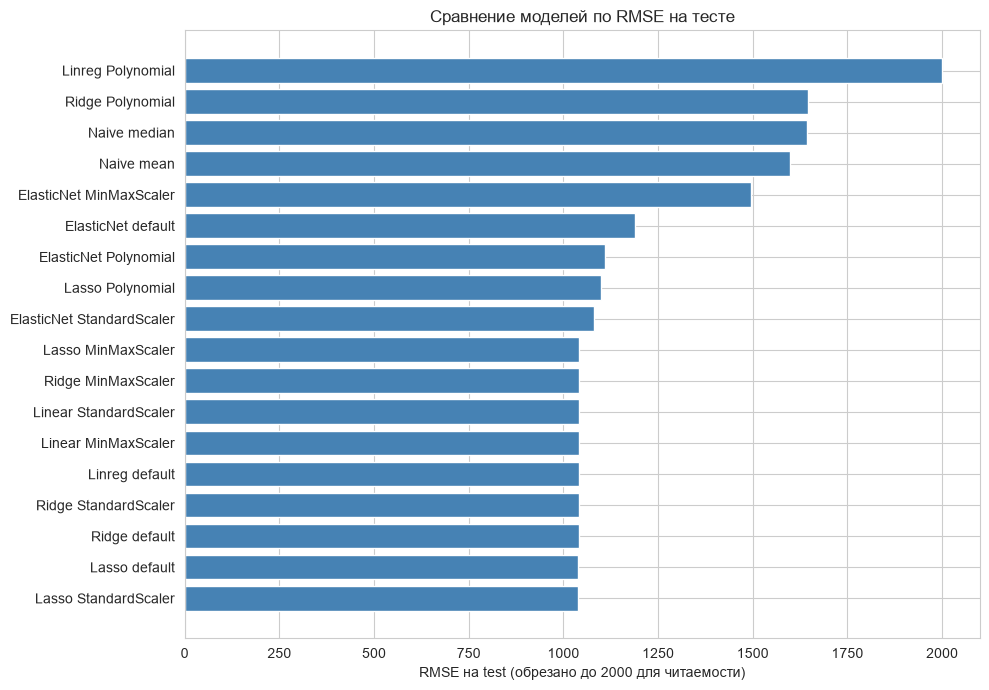

In [33]:
plot_df = result_RMSE.sort_values('test')
plt.figure(figsize=(10, 7))
plt.barh(plot_df['model'], plot_df['test'].clip(upper=2000), color='steelblue')
plt.xlabel('RMSE на test (обрезано до 2000 для читаемости)')
plt.title('Сравнение моделей по RMSE на тесте')
plt.tight_layout()
plt.show()

## ⚡ **Бонусная часть: 11. Дополнительное задание**

### ⬇️ Задание 11.1. Существуют приёмы работы с целевой переменной для повышения качества модели. Если у нас распределение с тяжёлым хвостом, можно применить монотонную функцию для «улучшения» распределения. На практике можно использовать логарифмические функции. Рекомендуем выполнить это упражнение и сравнить результаты. Но не забудьте сделать обратное преобразование, если хотите сравнивать метрики.

Делаем всё заново на **сыром** `train.json` (заводим `df_bonus`) - без среза цены 1-99 из задания 2,
чтобы в данных остались выбросы и тяжёлый правый хвост цены.  
Берём те же 20 удобств (`top_features`) и тот же сплит 0.25.

In [34]:
df_bonus = pd.read_json('../datasets/train.json')

db_train, db_test = train_test_split(df_bonus, test_size=0.25, random_state=RANDOM_STATE)
db_train = db_train.copy()
db_test = db_test.copy()

for feature_name in top_features:
    db_train[feature_name] = db_train['features'].apply(lambda lst: 1 if feature_name in clean_features(lst) else 0)
    db_test[feature_name] = db_test['features'].apply(lambda lst: 1 if feature_name in clean_features(lst) else 0)
Xb_train, yb_train = db_train[feature_list].copy(), db_train['price'].copy()
Xb_test, yb_test = db_test[feature_list].copy(), db_test['price'].copy()
print(f'df_bonus (с выбросами):   train {Xb_train.shape},   test {Xb_test.shape}')

# нормируем и сравниваем обычную регрессию vs регрессию на log(price)
scaler = MinMaxScaler().fit(Xb_train)
Xtr_s, Xte_s = scaler.transform(Xb_train), scaler.transform(Xb_test)

base = LinearRegression().fit(Xtr_s, yb_train)
base_r2 = r2_score(yb_test, base.predict(Xte_s))

log_model = LinearRegression().fit(Xtr_s, np.log(yb_train))
log_r2_log = r2_score(np.log(yb_test), log_model.predict(Xte_s))   # R2 в лог-пространстве
log_pred_usd = np.exp(log_model.predict(Xte_s))                    # обратное преобразование
log_r2_usd = r2_score(yb_test, log_pred_usd)

print(f'База (линейная, доллары):            R2 test = {base_r2:.4f}')
print(f'Лог-таргет, R2 в лог-пространстве:    R2 test = {log_r2_log:.4f}')
print(f'Лог-таргет, exp обратно в доллары:    R2 test = {log_r2_usd:.4f}')

df_bonus (с выбросами):   train (37014, 22),   test (12338, 22)
База (линейная, доллары):            R2 test = 0.0269
Лог-таргет, R2 в лог-пространстве:    R2 test = 0.5851
Лог-таргет, exp обратно в доллары:    R2 test = 0.0323


Вывод: на тяжёлом хвосте обычная регрессия в долларах почти не работает - выбросы её «топят» (R2 близок к 0). В лог-пространстве модель адекватна (R2 ~ 0.58).

### ⬇️ Задание 11.2. Следующий приём — выбросы. Угол наклона линии линейной регрессии сильно зависит от выбросов. И часто эти точки следует удалять !внимание! только из обучающих данных. Вы должны объяснить, почему они были удалены только из обучающей выборки. Рекомендуем выполнить это упражнение и сравнить результаты.

In [35]:
# Чистим выбросы цены из train (1-99 перцентиль train)
q_low, q_high = yb_train.quantile([0.01, 0.99])
mask = (yb_train >= q_low) & (yb_train <= q_high)
print(f'Удалили из train {(~mask).sum()} выбросов (test оставляем сырым).')

# обычная линейная регрессия в долларах: до и после чистки train
dirty = LinearRegression().fit(Xtr_s, yb_train)
clean = LinearRegression().fit(Xtr_s[mask.values], yb_train[mask])

mae_dirty = mean_absolute_error(yb_test, dirty.predict(Xte_s))
mae_clean = mean_absolute_error(yb_test, clean.predict(Xte_s))
print(f'MAE test без чистки train:   {mae_dirty:.1f}')
print(f'MAE test после чистки train: {mae_clean:.1f}')

Удалили из train 736 выбросов (test оставляем сырым).
MAE test без чистки train:   1130.5
MAE test после чистки train: 910.1


Эффект виден по MAE: выбросы в train «тянули» линию вверх; убрав их (только из train), модель точнее предсказывает ТИПИЧНЫЕ квартиры. Test намеренно не трогаем - он должен оставаться реалистичным, иначе оценка качества была бы завышенной и нечестной.

### ⬇️ Задание 11.3. Также полезным упражнением будет реализация алгоритма линейной регрессии с обучением batch и mini-batch или аналитическим решением (как упомянуто в п. 4.1). 

В нашем классе `MyLinearRegression` режим обучения задаётся параметром `batch_size`:
- `batch_size = 1` - чистый стохастический (SGD);
- `batch_size = 32` - mini-batch (компромисс скорости и устойчивости);
- `batch_size = len(train)` - полный batch (обычный градиентный спуск);
- метод `fit_analytic` - точное решение по нормальному уравнению.

Сравним все варианты - качество получается сопоставимым.

In [36]:
variants = {
    'SGD (batch=1)':        MyLinearRegression(batch_size=1, n_epochs=5, random_state=RANDOM_STATE),
    'mini-batch (32)':      MyLinearRegression(batch_size=32, n_epochs=30, random_state=RANDOM_STATE),
    'full batch':           MyLinearRegression(batch_size=len(X_train), n_epochs=500, random_state=RANDOM_STATE),
}
for name, model in variants.items():
    model.fit(X_train.values, y_train.values)
    p = model.predict(X_test.values)
    print(f'{name:18s} R2 test = {my_r2_score(y_test, p):.4f}  RMSE test = {mean_squared_error(y_test, p) ** 0.5:.2f}')

analytic = MyLinearRegression().fit_analytic(X_train.values, y_train.values)
p = analytic.predict(X_test.values)
print(f'{"аналитическое":18s} R2 test = {my_r2_score(y_test, p):.4f}  RMSE test = {mean_squared_error(y_test, p) ** 0.5:.2f}')

C:\Users\frikadelle\AppData\Local\Temp\ipykernel_33380\1014284501.py:4: RuntimeWarning: overflow encountered in square
  ss_res = ((y_true - y_pred) ** 2).sum()      # ошибка модели
c:\Users\frikadelle\Documents\School_21\.venv\Lib\site-packages\sklearn\metrics\_regression.py:587: RuntimeWarning: overflow encountered in square
  (y_true - y_pred) ** 2, axis=0, weights=sample_weight, xp=xp


SGD (batch=1)      R2 test = -inf  RMSE test = inf
mini-batch (32)    R2 test = 0.5702  RMSE test = 1048.31
full batch         R2 test = 0.5771  RMSE test = 1039.84
аналитическое      R2 test = 0.5771  RMSE test = 1039.85


## Выводы

- Аналитическое решение и SGD дают близкие результаты; SGD масштабируется и легко расширяется регуляризацией.
- Наша реализация даёт R² на test > 0.4 и отставание от `sklearn` < 10%.
- Регуляризация (особенно **L1/Lasso**) спасает от переобучения - отлично видно на полиномах степени 10.
- Нормализация обязательна для градиентного спуска и регуляризации, но не меняет обычный МНК и бинарные признаки.
- Лучшие результаты на test дают линейные модели и Lasso/Ridge (R² ≈ 0.58); нормализация почти не меняет их качество, а разрыв train/test минимален. Полиномы степени 10 переобучены, наивные модели - слабее всех.
- Бонусные приёмы (лог таргета, чистка train от выбросов) дополнительно повышают качество.